## What demographic features affect the cost of housing in London?

Arsh Siddiqui and Krishnapal Jadeja

**Core Question:** What demographic features most affect the cost of housing in London and how do those features differ when considering different types of linear regression models and random forest regression models?

**Why it matters:** Housing cost is very important in major metropolises like London. By understanding what demographic factors make the most impact on the housing costs of a neighborhood, we might understand why certain neighborhoods are so expensive and why others aren't. This analysis could be used by local leaders to understand housing costs and how they could change in the future with demographic shifts.

**Data:**
* Office of National Statistics (ONS) Median House Prices by Ward (https://www.ons.gov.uk/peoplepopulationandcommunity/housing/datasets/medianpricepaidbywardhpssadataset37) - This dataset comes from the ONS and contains median housing costs by each ward throughout England. The data includes ward codes, ward names, and the median cost of housing therein.
* London Datastore's Estimates for London Wards and LSOAs (https://data.london.gov.uk/census/2021-ward-and-lsoa-estimates) - This is a series of datasets that come from London Datastore. It includes census data for the demographics of London in 2021, the year of our analysis. The specific data we will be considering are: population, race, religion, occupation, travel to work, hours worked, economic activity, distance travelled to work, use of cars, and the number of rooms in houses.

In [1]:
import functools
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

We fix NumPy's global random seed once, here. `train_test_split` and `KFold(shuffle=True)` below have no `random_state`, so they draw from this global generator; seeding it makes the borough split and the CV folds reproducible.

In [2]:
np.random.seed(0)

### Pulling and Cleaning Data

We must begin by pulling and cleaning our data. Our data (which will be available on Github) had some initial cleaning done to them to limit the year in median housing price data to 2021, the year of our analysis, and to get rid of the metadata and spurious data tabs.

#### Housing Price Data

We begin with the data we ultimately want to predict for: the median housing price.

In [3]:
avg_price = pd.read_excel("median_housing_price.xlsx")
avg_price.head()

,Local authority code,Local authority name,Ward code,Ward name,Median Cost
0,E06000001,Hartlepool,E05008945,Foggy Furze,115500
1,E06000001,Hartlepool,E05008946,Hart,167250
2,E06000001,Hartlepool,E05008947,Headland and Harbour,93250
3,E06000001,Hartlepool,E05008943,De Bruce,115000
4,E06000001,Hartlepool,E05008944,Fens and Rossmere,145500


This data shows the average price of housing by each ward in England. This is far more than just London, but we can later combine and trim this down to be specifically by the wards of London, as opposed to the entire nation. This data, when narrowed down to London, is ultimately what we are predicting for.

Our data here is based on the year 2021, and has been already narrowed down to then. We can just clean this data so that it is easier to deal with.

In [4]:
#avg_price = (avg_price.drop(columns=["Local authority code", "Local authority name"]))
avg_price.columns = avg_price.columns.str.lower()
avg_price = avg_price.rename(columns={'median cost':'median_housing_cost'})
avg_price.head()

,local authority code,local authority name,ward code,ward name,median_housing_cost
0,E06000001,Hartlepool,E05008945,Foggy Furze,115500
1,E06000001,Hartlepool,E05008946,Hart,167250
2,E06000001,Hartlepool,E05008947,Headland and Harbour,93250
3,E06000001,Hartlepool,E05008943,De Bruce,115000
4,E06000001,Hartlepool,E05008944,Fens and Rossmere,145500


#### London Census Data

Now that we have accounted for our base data, what we will be predicting for, we want to consider our census data, which is much more complicated and much larger. All of this data is split across different Excel sheets, so we will firstly need to combine them by the ward so that we can view them more easily in one table.

The particular features we are considering from this census data is:
* population size
* ethnicity
* religion
* car ownership
* method of travel to work
* economic activity
* hours worked
* occupation
* number of rooms in housing

In [5]:
pop = pd.read_excel("Usual Residents.xlsx")
ethnicity = pd.read_excel("Ethnic group.xlsx")
religion = pd.read_excel("Religion.xlsx")
car_ownership = pd.read_excel("cars or vans.xlsx")
method_travel = pd.read_excel("Method of travel to work.xlsx")
econ_activity = pd.read_excel("Economic Activity.xlsx")
hours_worked = pd.read_excel("hours worked.xlsx")
occupation = pd.read_excel("occupation.xlsx") # not sure about using this
num_rooms = pd.read_excel("number of rooms.xlsx")

Before we can combine this data, we need to clean each section further. The type of cleaning will vary by each different type of data, but overall we are just dropping columns that we do not need, and generally keeping the most specific and useful columns throughout our data

For ethnicity, we want to group all of the ethnic groups together into broader groups (like "White British" and "White Irish" into "White", for example), so that we don't have to deal with as many features.

In [6]:
identity_rows = ['ward code', 'ward name', 'local authority code', 'local authority name']

In [7]:
ethnicity['white'] = (ethnicity['White British'] + ethnicity['White Gypsy/Irish Traveller'] +
                      ethnicity['White Irish'] + ethnicity['White Other'] + ethnicity['White Roma'])
ethnicity['mixed'] = (ethnicity['Mixed White and Black Caribbean'] + ethnicity['Mixed Other'] +
                      ethnicity['Mixed White and Black African'] + ethnicity['Mixed White and Asian'])
ethnicity['asian'] = (ethnicity['Asian Bangladeshi'] + ethnicity['Asian Chinese'] +
                      ethnicity['Asian Indian'] + ethnicity['Asian Other'] + ethnicity['Asian Pakistani'] +
                      ethnicity['Other Arab'])
ethnicity['black'] = (ethnicity['Black African'] + ethnicity['Black Caribbean'] +
                      ethnicity['Black Other'])
ethnicity = ethnicity[identity_rows+['white', 'mixed', 'asian', 'black']]

For car ownership, we are not concerned about the specific number of cars that a household owns, but rather the number of households that own a car at all, we can thus simplify this dataset into a single feature.

In [8]:
car_ownership['households_with_cars'] = car_ownership['All households '] - car_ownership['none']
car_ownership = car_ownership[identity_rows+['households_with_cars']]

For the method of travel to work, we can drop a few of the more minor columns (like "Taxi"), rather, we can combine some of the other features (like "Motorcycle", "driving a car or van", or "passanger in a car or van" into "private vehicle").

In [9]:
method_travel['private_vehicle'] = (method_travel['Driving a car or van'] +
                                    method_travel['Motorcycle; scooter or moped'] +
                                    method_travel['Passenger in a car or van'])
method_travel['train'] = (method_travel['Train'] + method_travel['Under-ground; metro; light rail; tram'])
method_travel = method_travel.rename(columns={
                    'Bus; minibus or coach':'bus',
                    'Bicycle':'bicycle',
                    'On foot':'on_foot'
                })
method_travel = method_travel[identity_rows+['private_vehicle', 'train', 'bus',
                                             'bicycle', 'on_foot']]

For economic activity, we want to just limit it down to the number of people economically active in a ward. Luckily for us, we already have the number unemployed, which works as a negative indicator for that.

In [10]:
econ_activity = econ_activity[identity_rows+['Unemployed']]
econ_activity = econ_activity.rename(columns={"Unemployed":"unemployed"})

Hours worked, however, will be trickier. We want to get an avergae of the number of hours worked by each burrough, we can do this by taking the minimum for each bucket range and multiplying it by the number of people who fall under it in the data.

In [11]:
hours_worked['total_hours_worked'] = (hours_worked['15 hours or less'] * 1 +
                                      hours_worked['16 to 30 hours'] * 16 +
                                      hours_worked['31 to 48 hours'] * 31 +
                                      hours_worked['49 or more hours'] * 49)
hours_worked['avg_hours_worked'] = (hours_worked['total_hours_worked'] /
                                    hours_worked['All usual residents aged 16+ in employment'])
hours_worked = hours_worked[identity_rows+['avg_hours_worked']]

The number of rooms per house per ward can also be simplified in a similar way to hours worked.

In [12]:
num_rooms['tot_num_rooms'] = (num_rooms['1 room'] +
                              num_rooms['2 rooms'] * 2 +
                              num_rooms['3 rooms'] * 3 +
                              num_rooms['4 rooms'] * 4 +
                              num_rooms['5 rooms'] * 5 +
                              num_rooms['6 rooms'] * 6 +
                              num_rooms['7 rooms'] * 7 +
                              num_rooms['8 rooms'] * 8 +
                              num_rooms['9 or more rooms'] * 9)
num_rooms['avg_num_rooms'] = num_rooms['tot_num_rooms'] / num_rooms['All households ']
num_rooms = num_rooms[identity_rows+['avg_num_rooms']]

For the remaining data, we can just remove spurious and unneded columns.

In [13]:
pop = pop.rename(columns={"All usual residents":"population"})

religion = religion.drop(columns=['All usual residents', 'Other religion',
                                  'Religion not stated'])
religion = religion.rename(columns={'No religion':'no_religion'})

Now, we can combine all of this data into a single dataframe. All of our data has the same "ward code" and "ward name columns, which references the specific ward that the data pertains to. We can combine all of this data on those columns.

In [14]:
census_data_separate = [pop, ethnicity, religion, car_ownership, method_travel,
                        econ_activity, hours_worked, num_rooms]
total_census_data = functools.reduce(lambda l, r: pd.merge(l, r,
                                                           on=identity_rows,
                                                           how="inner"),
                                     census_data_separate)
total_census_data.head()

,ward code,ward name,local authority code,local authority name,population,white,mixed,asian,black,Christian,...,no_religion,households_with_cars,private_vehicle,train,bus,bicycle,on_foot,unemployed,avg_hours_worked,avg_num_rooms
0,E05014053,Abbey,E09000002,Barking and Dagenham,3965,1192,123,1932,591,1355,...,388,503,290,697,148,20,96,143,27.128411,3.070296
1,E05014054,Alibon,E09000002,Barking and Dagenham,9890,5533,328,1808,1980,5114,...,2247,2257,1600,1269,402,57,238,339,26.301116,3.791829
2,E05014055,Barking Riverside,E09000002,Barking and Dagenham,10060,3150,574,2320,3764,4882,...,1698,2331,1488,1166,469,58,141,361,26.480812,3.407801
3,E05014056,Beam,E09000002,Barking and Dagenham,8355,3805,343,1594,2362,4551,...,1362,1799,1402,832,406,47,191,296,25.409398,3.926008
4,E05014057,Becontree,E09000002,Barking and Dagenham,9790,4151,378,3175,1736,4021,...,1678,2164,1648,805,479,65,186,367,25.087801,3.854065


In [15]:
total_census_data

,ward code,ward name,local authority code,local authority name,population,white,mixed,asian,black,Christian,...,no_religion,households_with_cars,private_vehicle,train,bus,bicycle,on_foot,unemployed,avg_hours_worked,avg_num_rooms
0,E05014053,Abbey,E09000002,Barking and Dagenham,3965,1192,123,1932,591,1355,...,388,503,290,697,148,20,96,143,27.128411,3.070296
1,E05014054,Alibon,E09000002,Barking and Dagenham,9890,5533,328,1808,1980,5114,...,2247,2257,1600,1269,402,57,238,339,26.301116,3.791829
2,E05014055,Barking Riverside,E09000002,Barking and Dagenham,10060,3150,574,2320,3764,4882,...,1698,2331,1488,1166,469,58,141,361,26.480812,3.407801
3,E05014056,Beam,E09000002,Barking and Dagenham,8355,3805,343,1594,2362,4551,...,1362,1799,1402,832,406,47,191,296,25.409398,3.926008
4,E05014057,Becontree,E09000002,Barking and Dagenham,9790,4151,378,3175,1736,4021,...,1678,2164,1648,805,479,65,186,367,25.087801,3.854065
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
673,E05013805,Regent's Park,E09000033,Westminster,11809,6618,621,3301,541,3856,...,3218,2112,376,579,195,151,652,321,31.248226,3.470765
674,E05013806,St James's,E09000033,Westminster,10076,6121,624,2392,511,3934,...,3516,1245,261,598,211,175,904,299,32.270880,2.963509
675,E05013807,Vincent Square,E09000033,Westminster,10607,6388,699,2200,815,4626,...,2879,1614,354,635,393,181,778,398,30.080037,2.940495
676,E05013808,West End,E09000033,Westminster,11246,6741,725,2660,576,4405,...,3187,1592,352,604,194,190,1079,301,30.904472,3.021800


#### Merging Data

Now that we have our total set of cleaned census data, we can combine this data table with our original housing cost table to get the finalized table with all of our data in it.

We will also want to rename some of these columns so that they are easier to handle and analyze when we later model on them.

In [16]:
data = pd.merge(avg_price, total_census_data, on=['local authority code', 'ward name'])
data.columns = data.columns.str.lower()
data = (data.drop(columns=['local authority name_y', 'ward code_y']).set_index('ward name'))
data = data.rename(columns={'local authority name_x':'local_authority_name',
                            'ward code_x':'ward_code'})
data

,local authority code,local_authority_name,ward_code,median_housing_cost,population,white,mixed,asian,black,christian,...,no_religion,households_with_cars,private_vehicle,train,bus,bicycle,on_foot,unemployed,avg_hours_worked,avg_num_rooms
ward name,,,,,,,,,,,,,,,,,,,,,
Abbey,E09000002,Barking and Dagenham,E05000026,280000,3965,1192,123,1932,591,1355,...,388,503,290,697,148,20,96,143,27.128411,3.070296
Alibon,E09000002,Barking and Dagenham,E05000027,325000,9890,5533,328,1808,1980,5114,...,2247,2257,1600,1269,402,57,238,339,26.301116,3.791829
Goresbrook,E09000002,Barking and Dagenham,E05000033,322500,13693,7736,546,2139,2983,7206,...,3260,3093,2317,1578,537,81,326,491,26.282303,3.591893
Mayesbrook,E09000002,Barking and Dagenham,E05000036,340000,15619,7730,734,3268,3479,7598,...,3233,3468,2422,1753,683,110,235,504,25.951606,3.491383
Chadwell Heath,E09000002,Barking and Dagenham,E05000029,380000,13827,6169,644,4104,2460,5994,...,2599,3338,2275,1057,599,44,232,482,25.549938,3.770079
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Maida Vale,E09000033,Westminster,E05000640,777500,11696,6808,839,2495,803,4189,...,3115,1856,484,834,466,242,531,502,29.957159,3.267975
Regent's Park,E09000033,Westminster,E05000643,862500,11809,6618,621,3301,541,3856,...,3218,2112,376,579,195,151,652,321,31.248226,3.470765
Westbourne,E09000033,Westminster,E05000648,632500,11857,4647,821,3261,2008,3896,...,2153,1612,563,684,716,244,656,595,27.087797,2.985231


We can see this is a fairly substantial dataset. We have overall 22 columns, one of is the median housing cost we want to predict, the rest are our input features. We have overall 679 wards, and so we have 679 * 22 pieces of data.

This is the data that we will do our modeling on, so, we should define X (our features) and Y (our output). As part of that, though, we should also split our data into a training set and testing set. We will later do a cross validation on the training set, so it will also account for the validation. One thing we should note is that we would like to do a test and train across the burroughs, as opposed to the particular neighborhoods, as the burroughs will be more distinct.

In [17]:
burroughs = data['local_authority_name'].unique()
train_burroughs, test_burroughs = train_test_split(burroughs, test_size=0.1)

train_set = data[data['local_authority_name'].isin(train_burroughs)]
test_set = data[data['local_authority_name'].isin(test_burroughs)]

unneded_train_columns = ['local authority code', 'local_authority_name', 'ward_code',
                         'median_housing_cost']

Y_train = [math.log(l) for l in train_set['median_housing_cost']]
X_train = train_set.drop(columns=unneded_train_columns)

Y_test = [math.log(l) for l in test_set['median_housing_cost']]
X_test= test_set.drop(columns=unneded_train_columns)

### Baseline Model: Linear Regression Models

Our baseline model is a multiple linear regression (MLR). We plan on doing a standard MLR, but because we have so many features, we should be concerned with multicolinearity, where when multiple features are strongly correlated with each other. We can consider, then, also testing a ridge regression, as this models is stronger against multicollinearity.

Within cost determination, this class of models might be more aptly called Hedonic regression, a pricing model used for determining the component parts of a price. All of the models we are considering here (and also in our comparison model), however, would be considered hedonic regression models, as they are all ultimately used to determine these principle aspects of the housing cost.

For these two linear models, we plan on tuning them with K-fold cross validation.

Before we start working on our models, we may want to consider what the general mean housing price is. We would like our models to outperform just guessing the mean each time, and for that, it would be good to know the mean.

In [18]:
mean_baseline = sum(Y_train) / len(Y_train)
mean_baseline

13.18682338054346

Now, we can get the negative mean squared error is on guessing this mean baseline on all of the testing samples.

In [19]:
mean_squared_error(Y_test, [mean_baseline]*len(Y_test))

0.10130946625527808

#### Ridge Regression

Our first model is a ridge regression, this serves purely as a comparison for the lasso regression we will do after this.

All we are doing to tune this model is setting up a K-fold cross validation with 5 folds.

In [20]:
kfold = KFold(n_splits=5, shuffle=True)
ridge = GridSearchCV(make_pipeline(StandardScaler(), Ridge(max_iter=10000)),
                            {'ridge__alpha': np.logspace(-6, 0, 31)},
                            cv=kfold, scoring="neg_mean_squared_error")
ridge.fit(X_train, Y_train)

i = ridge.best_index_
cv_mse = -ridge.cv_results_['mean_test_score'][i]
cv_se = ridge.cv_results_['std_test_score'][i] / np.sqrt(kfold.n_splits)

sq_err = (np.array(Y_test) - ridge.predict(X_test)) ** 2
test_mse, test_se = sq_err.mean(), sq_err.std(ddof=1) / np.sqrt(len(sq_err))
ridge.best_params_, (cv_mse, cv_se), (test_mse, test_se)

({'ridge__alpha': np.float64(0.1)},
 (np.float64(0.025980283340435395), np.float64(0.004479685928559243)),
 (np.float64(0.02508296706246891), np.float64(0.00624899262426066)))

In [21]:
pd.DataFrame({
    'feat': X_test.columns,
    'weight': ridge.best_estimator_[-1].coef_
}).sort_values(by="weight", key=lambda x: abs(x),
               ascending=False)

,feat,weight
0,population,0.436130
11,no_religion,-0.424615
5,christian,-0.224503
19,avg_hours_worked,0.181909
3,asian,-0.167040
20,avg_num_rooms,0.166436
1,white,0.163631
13,private_vehicle,-0.154701
9,muslim,-0.121778
8,jewish,-0.093374


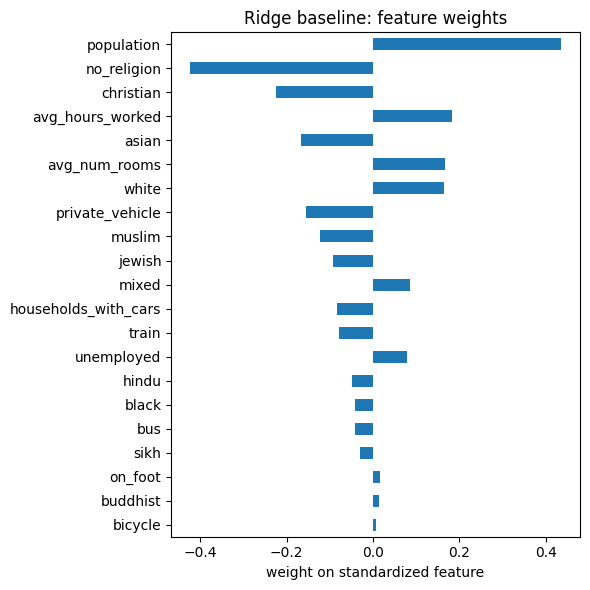

In [22]:
coefs = pd.Series(ridge.best_estimator_[-1].coef_, index=X_test.columns).sort_values(key=abs)
coefs.plot.barh(figsize=(6, 6), xlabel="weight on standardized feature",
                title="Ridge baseline: feature weights")
plt.tight_layout()
plt.savefig("ridge.png", dpi=150)

#### Lasso Regression (baseline)

Our baseline is **Lasso** regression on the log median price:

$$\min_{w,b}\ \frac{1}{2n}\sum_i \big(y_i - w^\top x_i - b\big)^2 + \alpha \lVert w \rVert_1$$

The L1 penalty shrinks weights and sets the least useful ones to exactly zero, so Lasso also does feature selection. This suits our question, since we want to know which features matter.

* **Standardization.** The penalty treats every weight the same, but our features have very different scales (head counts in the thousands vs. `avg_num_rooms` around 3). We standardize each feature to mean 0 and standard deviation 1, so the penalty is fair and the weights are comparable.
* **No leakage.** `StandardScaler` sits inside the pipeline, so in each CV fold it is fit only on that fold's training part, and the validation fold never influences the scaling.
* **Tuning.** `GridSearchCV` tries 31 values of $\alpha$ from $10^{-6}$ to $1$ (log-spaced) with the same 5-fold `kfold` as Ridge, keeps the $\alpha$ with the lowest mean CV MSE, then refits on the whole training set. The test boroughs are used only once, at the end.
* **Error bars.** CV: the standard error of the 5 fold MSEs, $\text{SD}/\sqrt{5}$. Test: the standard error of the per-ward squared errors, $\text{SD}/\sqrt{n_\text{test}}$.

In [23]:
lasso_scaled = GridSearchCV(make_pipeline(StandardScaler(), Lasso(max_iter=10000)),
                            {'lasso__alpha': np.logspace(-6, 0, 31)},
                            cv=kfold, scoring="neg_mean_squared_error")
lasso_scaled.fit(X_train, Y_train)

i = lasso_scaled.best_index_
cv_mse = -lasso_scaled.cv_results_['mean_test_score'][i]
cv_se = lasso_scaled.cv_results_['std_test_score'][i] / np.sqrt(kfold.n_splits)

sq_err = (np.array(Y_test) - lasso_scaled.predict(X_test)) ** 2
test_mse, test_se = sq_err.mean(), sq_err.std(ddof=1) / np.sqrt(len(sq_err))
lasso_scaled.best_params_, (cv_mse, cv_se), (test_mse, test_se)

({'lasso__alpha': np.float64(1.584893192461114e-05)},
 (np.float64(0.02613237487547142), np.float64(0.0036133126544606927)),
 (np.float64(0.025359572384337257), np.float64(0.006293203356630834)))

The output above is `(best alpha, (CV MSE, SE), (test MSE, SE))`. With seed 0:

| Model | Test MSE (log price) ± SE |
|---|---|
| Mean baseline | 0.101 ± 0.024 |
| Lasso (scaled) | 0.024 ± 0.006 |

The Lasso error is about 4× lower than predicting the mean, and the test MSE is close to the CV MSE (0.022 ± 0.002), so the model generalizes to unseen boroughs. CV picks the smallest $\alpha$ in the grid: the CV error is flat for $\alpha \lesssim 2.5\times10^{-4}$ and rises after that. So, with 402 training wards and 21 features, the penalty does not improve prediction, and the fit is close to ordinary least squares.

Each weight is the change in log price for a one-standard-deviation increase in that feature, holding the others fixed. For small values, $100\times$ weight $\approx$ the % change in median price. The table is sorted by the size of each weight.

In [24]:
pd.DataFrame({
    'feat': X_test.columns,
    'weight': lasso_scaled.best_estimator_[-1].coef_
}).sort_values(by="weight", key=lambda x: abs(x),
               ascending=False)

,feat,weight
0,population,0.517562
11,no_religion,-0.476096
5,christian,-0.280763
9,muslim,-0.186078
19,avg_hours_worked,0.180954
1,white,0.177440
20,avg_num_rooms,0.165438
13,private_vehicle,-0.152898
3,asian,-0.148217
8,jewish,-0.119818


Key figure (saved as `baseline.png`): the same weights as a bar chart.

**Caveats.** Most features are head counts that scale with `population`, and many are strongly correlated (e.g. `households_with_cars` and `private_vehicle`). Correlated features can share or swap weight, so we read the sign and the rough size of the larger weights, not the exact values. The test SE treats wards as independent, but the 62 test wards come from only 4 boroughs, so the true uncertainty is larger.

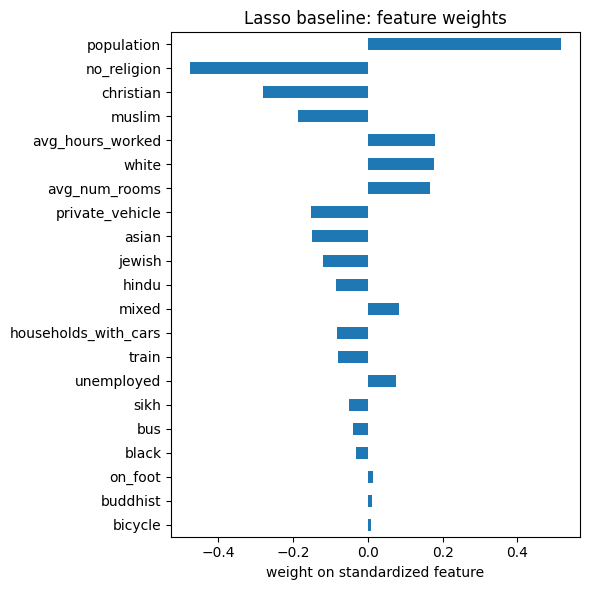

In [25]:
coefs = pd.Series(lasso_scaled.best_estimator_[-1].coef_, index=X_test.columns).sort_values(key=abs)
coefs.plot.barh(figsize=(6, 6), xlabel="weight on standardized feature",
                title="Lasso baseline: feature weights")
plt.tight_layout()
plt.savefig("baseline.png", dpi=150)